In [1]:
# ติดตั้งแพ็กเกจเมื่อรันใน repo — บน Kaggle มี pandas/matplotlib พร้อมอยู่แล้ว
from pathlib import Path

if Path("requirements-offline.txt").exists():
    get_ipython().run_line_magic(
        "pip", "install -r requirements-offline.txt --quiet")
else:
    print("ข้ามการติดตั้ง — ใช้แพ็กเกจที่มีใน environment (เช่น Kaggle)")

ข้ามการติดตั้ง — ใช้แพ็กเกจที่มีใน environment (เช่น Kaggle)


# Module M4 — กราฟที่สื่อสารได้

|  |  |
|---|---|
| **เวลา** | Day 1 (75 นาที) · Offline (CPU) |
| **ข้อมูล** | Palmer Penguins · Gapminder |

**เมื่อจบโมดูลนี้ ผู้เรียนจะ...**

- เลือกชนิดกราฟให้ตรงกับคำถาม (scatter · bar · line · histogram)
- ใส่ตัวแปรที่สามลงในกราฟด้วย**สี** แล้วอ่านความหมายที่ซ่อนอยู่
- จับกับดักกราฟที่ "หลอกตา" และแก้ให้ซื่อสัตย์
- ส่งออกกราฟเป็นไฟล์ PNG พร้อมป้ายครบ ไปใช้ในรายงาน

**บทบาทของโมดูลนี้:** ผลลัพธ์ปิดวันที่ 1 — รูปแรกที่คุณวาดเองจากข้อมูลจริง
ใช้เพียงทักษะ M1–M3 ที่เพิ่งเรียน (อ่านไฟล์ · ตาราง `groupby` · ข้อมูลสะอาด) —
สถิติคือ M5 พรุ่งนี้ ไม่ต้องรอ

**ข้อมูลที่ใช้ (citation):**

> Gorman, K. B., Williams, T. D. & Fraser, W. R. (2014). *Ecological
> sexual dimorphism and environmental variation within a common species
> biomass range: Antarctic penguins*. PLoS ONE 9(3):e90081 (CC0-1.0)
>
> Gapminder Foundation. *Life expectancy, GDP per capita & population*
> (excerpt 1952–2007), https://www.gapminder.org/free-material/ (CC BY 4.0)

## 1. เลือกกราฟจากคำถาม — ไม่ใช่จากความสวย

คำถามที่เราต้องการตอบกำหนดชนิดกราฟ:

| คำถาม | ตัวแปร | กราฟ |
|---|---|---|
| "สองตัวเลขนี้สัมพันธ์กันไหม" | ตัวเลข × ตัวเลข | **scatter** (จุดกระจาย) |
| "กลุ่มไหนมากกว่ากัน" | หมวดหมู่ × ตัวเลข | **bar** (แท่ง) |
| "มันเปลี่ยนไปตามเวลาอย่างไร" | เวลา × ตัวเลข | **line** (เส้น) |
| "ค่าทั้งหมดกระจายหน้าตาอย่างไร" | ตัวแปรเดียว | **histogram** (ใหม่ในโมดูลนี้) |

เลือกผิด = ผู้อ่านตอบคำถามผิด — ไม่ใช่แค่ "สวยน้อยกว่า" เฉย ๆ

In [2]:
import pandas as pd
from pathlib import Path

import os


def data_root() -> Path:
    """หาโฟลเดอร์ datasets/ — ใช้ได้ทั้ง repo local, venv และ Kaggle.

    ลำดับการค้นหา:
    1. environment variable COURSE_DATA_ROOT (ชี้ตรงไปที่โฟลเดอร์ datasets)
    2. โฟลเดอร์ datasets/ ที่อยู่ระดับเดียวกับโน้ตบุ๊กหรือแม่ขึ้นไป
       (repo local)
    3. /kaggle/input — ทั้งกรณีอัปโหลด datasets/ ทั้งโฟลเดอร์
       หรืออัปโหลดแต่ละชุดแยกกัน (ชื่อโฟลเดอร์ต้องตรงกับใน datasets/)
    """
    env = os.environ.get("COURSE_DATA_ROOT")
    if env:
        return Path(env)
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "datasets").is_dir():
            return p / "datasets"
    kaggle = Path("/kaggle/input")
    if kaggle.is_dir():
        hits = sorted(kaggle.glob("**/datasets"))
        if hits:
            return hits[0]
        return kaggle
    raise SystemExit(
        "ไม่พบโฟลเดอร์ datasets/ — ตั้ง COURSE_DATA_ROOT "
        "หรือวาง datasets/ ไว้ข้างโน้ตบุ๊ก")

PENG = data_root() / "palmer_penguins"
GAP = data_root() / "gapminder"

penguins = pd.read_csv(PENG / "penguins.csv").dropna()
gapminder = pd.read_csv(GAP / "gapminderDataFiveYear.csv")
print(f"penguins {penguins.shape}, gapminder {gapminder.shape}")

penguins (333, 8), gapminder (1704, 6)


## 2. scatter — ความสัมพันธ์ของสองตัวแปรตัวเลข

คำถาม: เพนกวินที่**แผ่นปีกยาวกว่า** หนัก**กว่า**จริงไหม?

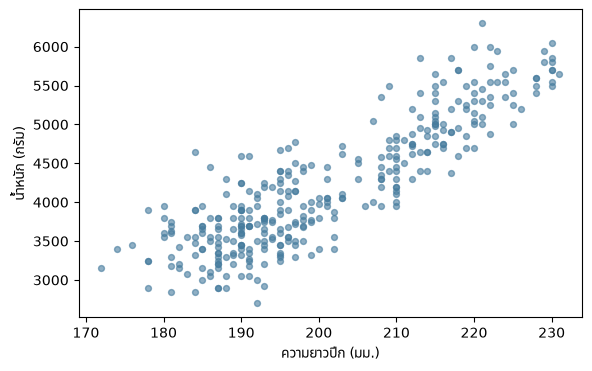

In [3]:
import matplotlib.pyplot as plt  # noqa: E402

plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(penguins["flipper_length_mm"], penguins["body_mass_g"],
           s=18, alpha=0.6, color="#457b9d")

ax.set_xlabel("ความยาวปีก (มม.)")
ax.set_ylabel("น้ำหนัก (กรัม)")
plt.show()

จุดพาดขึ้นขวา = **สัมพันธ์บวก**: ปีกยาวกว่า → หนักกว่า (แนวโน้มชัด
แต่ไม่ใช่กฎเหล็ก — จุดเบี่ยงอยู่รอบ ๆ เส้นแนวโน้มเสมอ)

แต่มีบางอย่างแปลก: จุดดูแน่นเป็นสองกลุ่มแยกกัน — อะไรซ่อนอยู่?

### สี = ตัวแปรที่สาม

เรามีตัวแปรที่สาม (`species`) — วิธีใส่ลงกราฟสองมิติ: วาดแยกสีตามกลุ่ม
วนเฉดด้วย `for` แล้วประกาศชื่อกลุ่มด้วย `label` ให้ `legend()` อ่านออก:

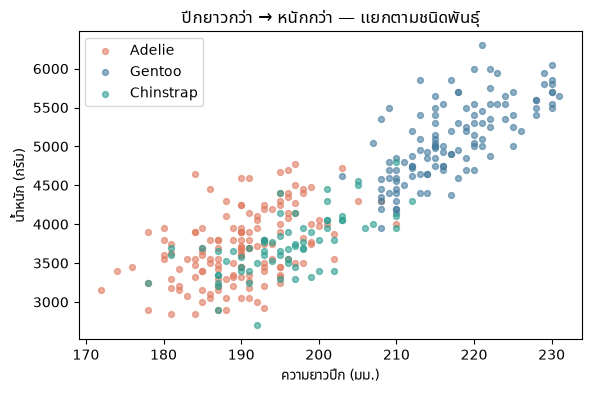

In [4]:
colors = {"Adelie": "#e07a5f", "Gentoo": "#457b9d",
          "Chinstrap": "#2a9d8f"}

fig, ax = plt.subplots(figsize=(6.5, 4))
for species_name, color in colors.items():
    mask = penguins["species"] == species_name
    subset = penguins[mask]
    ax.scatter(subset["flipper_length_mm"], subset["body_mass_g"],
               s=18, alpha=0.6, color=color, label=species_name)
ax.legend()
ax.set_xlabel("ความยาวปีก (มม.)")
ax.set_ylabel("น้ำหนัก (กรัม)")
ax.set_title("ปีกยาวกว่า → หนักกว่า — แยกตามชนิดพันธุ์")
plt.show()

## ✏️ ลองเอง 1 — scatter: ปีกกับน้ำหนัก

ใช้ `penguins` วาด scatter ของ `flipper_length_mm` (แกน x) กับ `body_mass_g` (แกน y) พร้อมใส่ชื่อกราฟและป้ายแกนทั้งสองข้างให้ครบ

**คำใบ้:** ใช้ `ax.scatter(penguins["flipper_length_mm"], penguins["body_mass_g"])` แล้วตามด้วย `ax.set_xlabel(...)`, `ax.set_ylabel(...)` และ `ax.set_title(...)`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# ผลที่ต้องได้: กราฟจุดกระจายที่มีชื่อกราฟและป้ายแกน x, y ครบทั้งสองข้าง

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

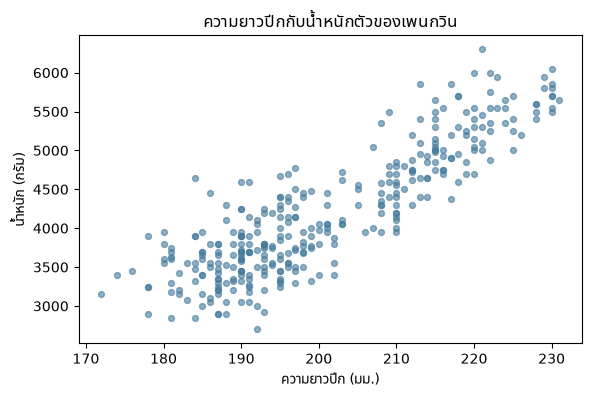

</div>

## ✏️ ลองเอง 2 — scatter: ความยาวจะงอยปากกับความลึกจะงอยปาก

วาด scatter ระหว่าง `bill_length_mm` (แกน x) กับ `bill_depth_mm` (แกน y) กำหนดสีจุดเป็น `#2a9d8f` และขนาดจุด `s=20` พร้อมตั้งชื่อแกน x เป็น "ความยาวจะงอยปาก (มม.)" และแกน y เป็น "ความลึกจะงอยปาก (มม.)"

**คำใบ้:** ไวยากรณ์วาด scatter เดี่ยวคือ `ax.scatter(x, y, s=20, color="#2a9d8f", alpha=0.6)` แล้วตั้งชื่อแกนด้วย `ax.set_xlabel(...)` และ `ax.set_ylabel(...)`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# วาด scatter ของ bill_length_mm กับ bill_depth_mm พร้อมป้ายแกน x, y

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

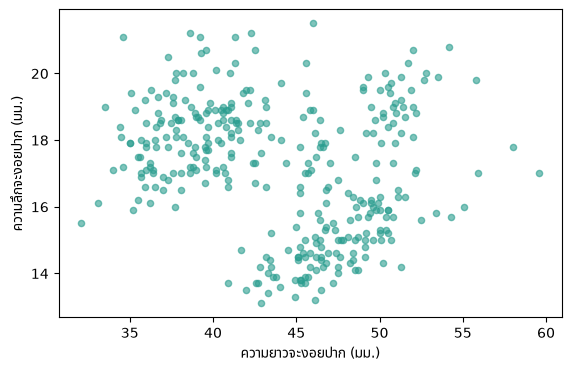

</div>

อ่านได้เพิ่มทันที:

- **Gentoo** (น้ำเงิน) อยู่มุมขวา — ปีกยาว **และ** หนักกว่าทุกชนิด แยกออกเป็นกลุ่มของตัวเอง
- **Adelie vs Chinstrap** (ส้ม/เขียว) ปีกยาวใกล้กัน — ซ้อนกันเป็นแถบเดียว
  (M5 พรุ่งนี้จะยืนยันด้วยตัวเลข — ต่างกันที่ bill_depth ไม่ใช่ปีก)

กราฟเดียวกัน ไม่ใส่สี = เห็นเมฆเดียว ใส่สี = เห็นสามเรื่องพร้อมกัน

## 3. bar — เปรียบเทียบกลุ่ม (กราฟจากตารางสรุปของ M2)

คำถาม: ชนิดไหนหนักกว่ากัน เท่าไหร่? คำตอบอยู่ใน `groupby` ที่เราทำเป็นแล้ว —
เหลือแค่เปลี่ยนตารางเป็นแท่ง:

species
Adelie       3706.164384
Chinstrap    3733.088235
Gentoo       5092.436975
Name: body_mass_g, dtype: float64


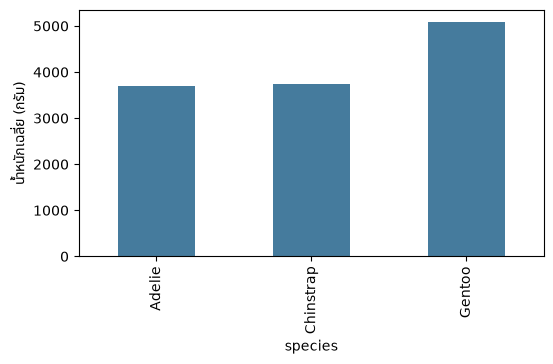

In [6]:
means = penguins.groupby("species")["body_mass_g"].mean()
print(means)
fig, ax = plt.subplots(figsize=(6, 3.2))
means.plot.bar(ax=ax, color="#457b9d")
ax.set_ylabel("น้ำหนักเฉลี่ย (กรัม)")
plt.show()

## ✏️ ลองเอง 3 — bar: น้ำหนักเฉลี่ยแยกตามเพศ

คำนวณน้ำหนักเฉลี่ย `body_mass_g` แยกตามเพศ `sex` ของเพนกวิน แล้ววาดเป็นกราฟแท่งด้วย `.plot.bar()` พร้อมตั้งชื่อแกน y เป็น "น้ำหนักเฉลี่ย (กรัม)"

**คำใบ้:** ไวยากรณ์สรุปและพล็อตคือ `penguins.groupby("sex")["body_mass_g"].mean().plot.bar(ax=ax, color="#e07a5f")`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# สรุปน้ำหนักเฉลี่ยแยกตาม sex แล้ววาดกราฟแท่งพร้อมป้ายแกน y

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

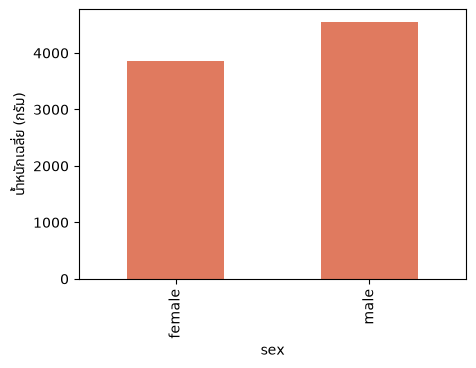

</div>

### สรุปหลายค่าสถิติด้วย `groupby` + `.agg()` (min, mean, max)

ค่าเฉลี่ยเพียงอย่างเดียวอาจบอกภาพไม่ครบ — เรามักอยากรู้ทั้งค่าต่ำสุด (min), ค่าเฉลี่ย (mean/average) และค่าสูงสุด (max) ของแต่ละกลุ่ม
คำสั่ง `.agg()` ที่เรียนใน M2 ช่วยรวมสถิติเหล่านี้ออกมาเป็นตารางเดียว:

In [7]:
mass_stats = penguins.groupby("species")["body_mass_g"].agg(
    min_mass="min",
    avg_mass="mean",
    max_mass="max",
)
print(mass_stats)

           min_mass     avg_mass  max_mass
species                                   
Adelie       2850.0  3706.164384    4775.0
Chinstrap    2700.0  3733.088235    4800.0
Gentoo       3950.0  5092.436975    6300.0


เมื่อตารางสรุปมีหลายคอลัมน์ การเรียก `.plot.bar()` จะสร้าง**กราฟแท่งแบบกลุ่ม (Grouped Bar Chart)** ให้อัตโนมัติ — เห็นทั้งช่วง min–max และค่าเฉลี่ยเทียบกันทันที:

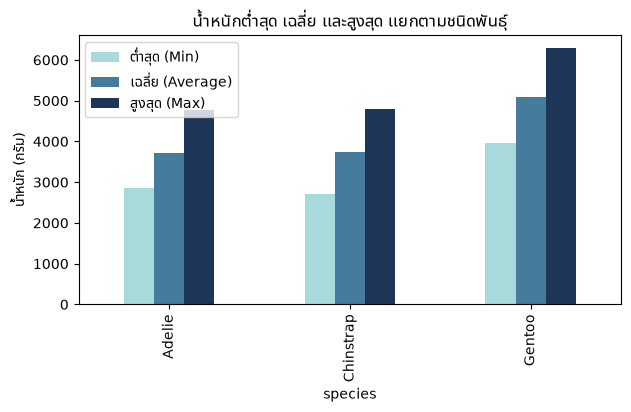

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
mass_stats.plot.bar(ax=ax, color=["#a8dadc", "#457b9d", "#1d3557"])
ax.set_ylabel("น้ำหนัก (กรัม)")
ax.set_title("น้ำหนักต่ำสุด เฉลี่ย และสูงสุด แยกตามชนิดพันธุ์")
ax.legend(["ต่ำสุด (Min)", "เฉลี่ย (Average)", "สูงสุด (Max)"])
plt.show()

## ✏️ ลองเอง 4 — bar: กราฟแท่งแนวนอน (barh)

นำตาราง `mass_stats` มาวาดเป็นกราฟแท่งแนวนอนด้วย `.plot.barh()` พร้อมตั้งชื่อกราฟว่า "สถิติน้ำหนักเพนกวินแนวนอน"

**คำใบ้:** ไวยากรณ์วาดกราฟแท่งแนวนอนคือ `mass_stats.plot.barh(ax=ax)` และตั้งชื่อกราฟด้วย `ax.set_title("...")`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# วาด mass_stats เป็นกราฟแท่งแนวนอนด้วย .plot.barh() พร้อมชื่อกราฟ

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

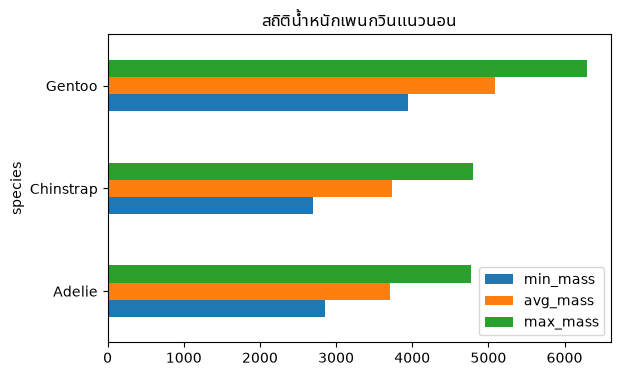

</div>

อ่านกราฟแท่งแบบกลุ่ม:

- **Gentoo** เหนือกว่าทุกช่วงอย่างชัดเจน — แม้ค่าน้ำหนักต่ำสุดของ Gentoo (3,950 กรัม) ยังสูงกว่าค่าเฉลี่ยของ Adelie และ Chinstrap (~3,700 กรัม)
- **Adelie vs Chinstrap** มีช่วงน้ำหนักแทบจะขนานกันและเกาะกลุ่มเดียวกัน

### สรุปทีละหลายคอลัมน์พร้อมกัน

ถ้าต้องการเปรียบเทียบสัดส่วนร่างกายหลายด้านพร้อมกัน เราสามารถเลือกหลายคอลัมน์ เช่น ความยาวจะงอยปาก (`bill_length_mm`), ความลึกจะงอยปาก (`bill_depth_mm`) และความยาวปีก (`flipper_length_mm`) มาสรุปพร้อมกันได้:

           bill_length_mm  bill_depth_mm  flipper_length_mm
species                                                    
Adelie          38.823973      18.347260         190.102740
Chinstrap       48.833824      18.420588         195.823529
Gentoo          47.568067      14.996639         217.235294


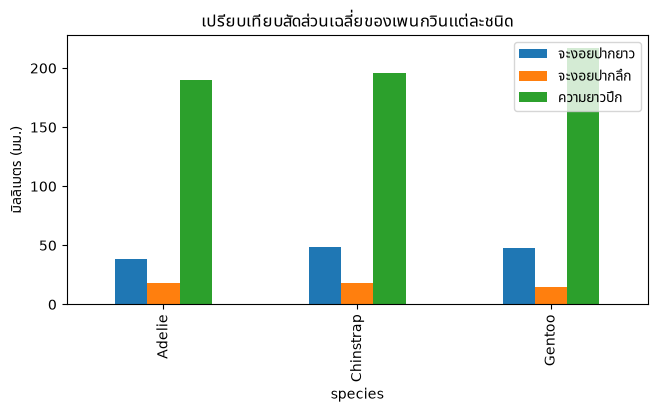

In [9]:
dim_means = penguins.groupby("species")[
    ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]
].mean()
print(dim_means)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
dim_means.plot.bar(ax=ax)
ax.set_ylabel("มิลลิเมตร (มม.)")
ax.set_title("เปรียบเทียบสัดส่วนเฉลี่ยของเพนกวินแต่ละชนิด")
ax.legend(["จะงอยปากยาว", "จะงอยปากลึก", "ความยาวปีก"])
plt.show()

ภาพเดียวตอบได้ 3 มิติ:

- Gentoo ปีกยาวที่สุดชัดเจน (~217 มม.) แต่จะงอยปากกลับตื้นที่สุด (~15 มม.)
- Chinstrap มีความยาวจะงอยปากโดดเด่นกว่า Adelie ชัดเจน (~49 มม. vs ~39 มม.) แม้ความยาวปีกจะใกล้เคียงกัน

### กับดักกราฟแท่ง: แกน y ไม่เริ่มที่ศูนย์

ลองย่อแกนให้เริ่มที่ 3,000 — ข้อมูลชุดเดิมเป๊ะ แต่ความหมายเปลี่ยนสิ้นเชิง:

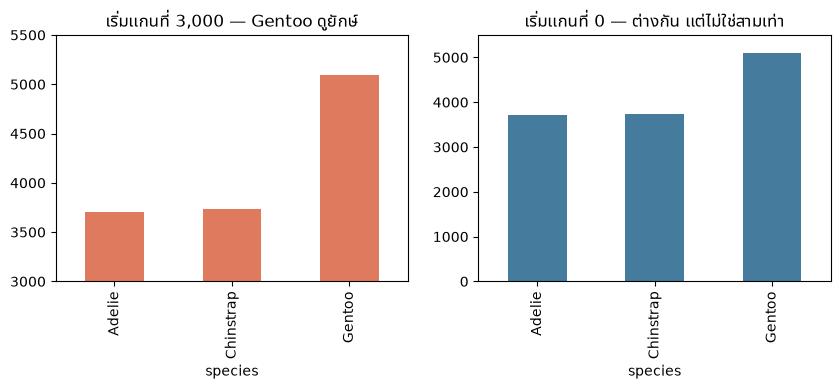

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))

means.plot.bar(ax=axes[0], color="#e07a5f")
axes[0].set_ylim(3000, 5500)          # ตัดฐานทิ้ง — เทคนิคที่ข่าวชอบใช้
axes[0].set_title("เริ่มแกนที่ 3,000 — Gentoo ดูยักษ์")

means.plot.bar(ax=axes[1], color="#457b9d")
axes[1].set_ylim(0, 5500)             # แกนซื่อสัตย์: เริ่มที่ศูนย์
axes[1].set_title("เริ่มแกนที่ 0 — ต่างกัน แต่ไม่ใช่สามเท่า")

plt.show()

## ✏️ ลองเอง 5 — bar: แกน y ต้องเริ่มที่ศูนย์

คำนวณน้ำหนักเฉลี่ย `body_mass_g` แยกตาม `species` ด้วย `groupby` แล้ววาดเป็นกราฟแท่ง โดยให้แกน y เริ่มที่ 0

**คำใบ้:** สร้าง `means` แบบเดียวกับในบทเรียน แล้วเรียก `means.plot.bar(ax=ax)` ต่อด้วย `ax.set_ylim(bottom=0)`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# ผลที่ต้องได้: กราฟแท่ง 3 แท่ง (Adelie, Chinstrap, Gentoo)
# ที่ฐานของทุกแท่งเริ่มที่ 0


<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

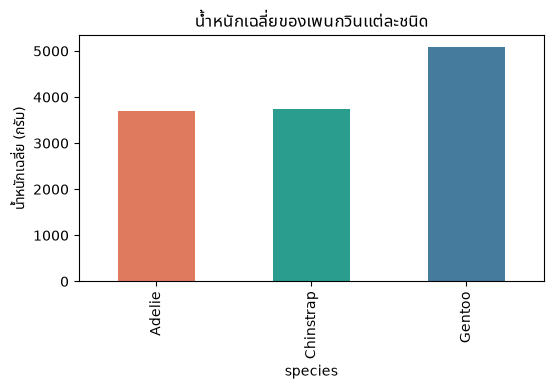

</div>

ซ้ายทำให้ Gentoo ดู "หนักกว่าห่างสามเท่า" — จริง ๆ ต่างเพียง ~35%

**กฎ:** กราฟแท่งวัดด้วย**ความยาวแท่ง** แท่งจึงต้องเริ่มที่ศูนย์เสมอ
ถ้าความต่างเล็กจนมองไม่เห็นบนแกนจริง — นั่นคือความจริงของข้อมูล
อย่าแก้ด้วยการตัดฐาน ให้แสดงตัวเลขกำกับแทน

(กราฟเส้นไม่ผูกกับกฎนี้ — ตัดแกน y ได้ เพราะเราอ่าน**ความชัน** ไม่ใช่ความยาว)

## 4. line — แนวโน้มตามเวลา (Gapminder)

คำถาม: ความคาดหวังชีวิตของไทยดีขึ้นตามเวลาจริงไหม — เร็วเท่าประเทศเพื่อนบ้าน?

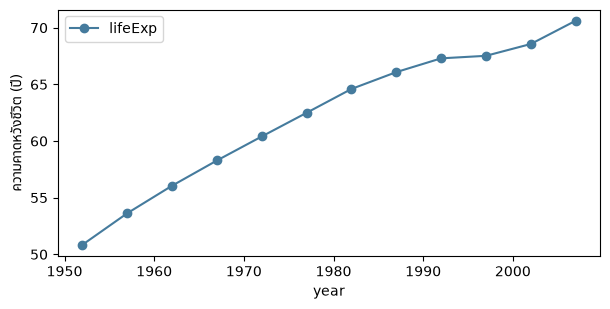

In [12]:
th = gapminder[gapminder["country"] == "Thailand"]

fig, ax = plt.subplots(figsize=(7, 3.2))
th.plot.line(x="year", y="lifeExp", ax=ax, color="#457b9d", marker="o")
ax.set_ylabel("ความคาดหวังชีวิต (ปี)")
plt.show()

## ✏️ ลองเอง 6 — line: แนวโน้ม GDP ต่อหัวของประเทศไทย

จาก `th` (ข้อมูลประเทศไทย) จงวาดกราฟเส้นแสดงแนวโน้ม `gdpPercap` ตามเวลา `year` โดยกำหนดจุดเป็นสี่เหลี่ยม `marker="s"` และตั้งป้ายแกน y เป็น "GDP ต่อหัว (USD)"

**คำใบ้:** ไวยากรณ์วาดกราฟเส้นคือ `ax.plot(th["year"], th["gdpPercap"], color="#2b6cb0", marker="s")` และตั้งป้ายแกน y ด้วย `ax.set_ylabel(...)`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# วาดกราฟเส้น gdpPercap ของประเทศไทยตามปี (marker='s') พร้อมป้ายแกน y

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

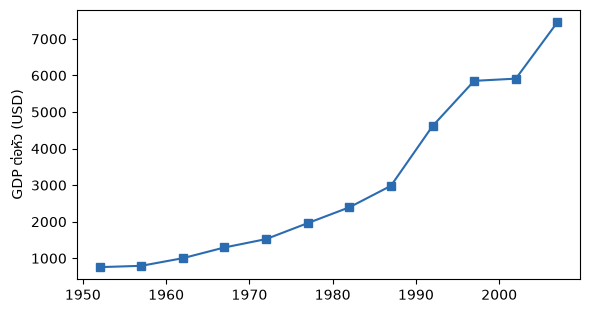

</div>

ขึ้นสม่ำเสมอจาก ~56 ปี (1952) มา ~70 ปี (2007)

เส้นเดียวบอกแนวโน้ม แต่ "เร็วกว่าเพื่อนไหม" ต้องมีเพื่อนบ้าง — วนเพิ่มสองประเทศ:

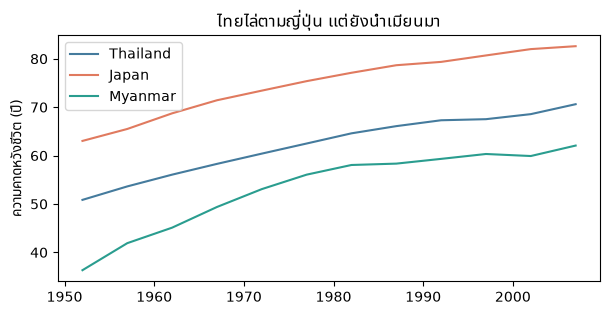

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for country_name, color in [("Thailand", "#457b9d"),
                            ("Japan", "#e07a5f"),
                            ("Myanmar", "#2a9d8f")]:
    one = gapminder[gapminder["country"] == country_name]
    ax.plot(one["year"], one["lifeExp"], color=color,
            label=country_name)
ax.legend()
ax.set_ylabel("ความคาดหวังชีวิต (ปี)")
ax.set_title("ไทยไล่ตามญี่ปุ่น แต่ยังนำเมียนมา")
plt.show()

## ✏️ ลองเอง 7 — line: เปรียบเทียบ GDP ต่อหัว ไทย vs เวียดนาม

วาดกราฟเส้นเปรียบเทียบ `gdpPercap` ระหว่าง `"Thailand"` และ `"Vietnam"` โดยใช้สีต่างกัน กำหนดป้ายชื่อด้วย `label` และแสดงกล่องคำอธิบายด้วย `ax.legend()`

**คำใบ้:** กรองข้อมูลของแต่ละประเทศแล้วเรียก `ax.plot(df["year"], df["gdpPercap"], label="...")` ทีละเส้น แล้วเรียก `ax.legend()`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# วาดกราฟเส้นเปรียบเทียบ GDP ต่อหัวของ Thailand กับ Vietnam พร้อม legend

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

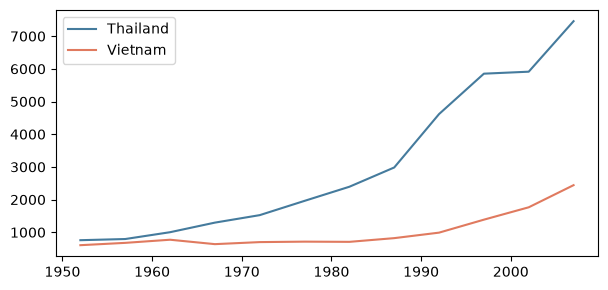

</div>

อ่านสามเส้นพร้อมกัน:

- **ญี่ปุ่น** สูงตั้งแต่ต้น และไม่ดิ่งลง (ข้อมูลชุดนี้มาถึงปี 2007)
- **ไทย** ไล่จากหลังไล่ตามแนวขนานญี่ปุ่นพอดี
- **เมียนมา** เส้นเดียวกันแต่ช้ากว่า — และมีช่วงตกลงกลางทศวรรษ 2000

สามประโยคนี้คือสิ่งที่กราฟสื่อสารได้ทันที ซึ่งตาราง 504 แถวสื่อไม่ได้

## 5. ป้ายครบ แล้วส่งออกเป็นไฟล์

กราฟที่วางในโน้ตบุ๊กดูได้ในห้อง — แต่รายงาน (Word/PDF/สไลด์) ต้องการ**ไฟล์ภาพ**:

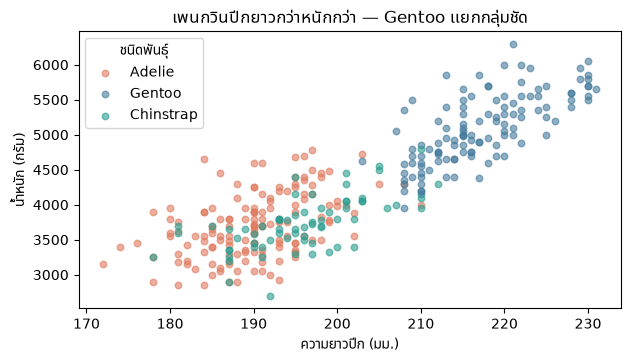

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for species_name, color in colors.items():
    mask = penguins["species"] == species_name
    subset = penguins[mask]
    ax.scatter(subset["flipper_length_mm"], subset["body_mass_g"],
               s=22, alpha=0.6, color=color, label=species_name)
ax.legend(title="ชนิดพันธุ์")
ax.set_xlabel("ความยาวปีก (มม.)")
ax.set_ylabel("น้ำหนัก (กรัม)")
ax.set_title("เพนกวินปีกยาวกว่าหนักกว่า — Gentoo แยกกลุ่มชัด")
plt.savefig("penguins_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## ✏️ ลองเอง 8 — เพิ่มเส้นกริดและส่งออกกราฟเป็นไฟล์ภาพ

นำกราฟเส้นของประเทศไทยมาเพิ่มเส้นตารางประด้วย `ax.grid(True, linestyle="--", alpha=0.5)` แล้วบันทึกเป็นไฟล์ภาพ `"thai_gdp_trend.png"` ที่ความละเอียด `dpi=150`

**คำใบ้:** ไวยากรณ์เปิดเส้นกริดคือ `ax.grid(True, linestyle="--", alpha=0.5)` และบันทึกไฟล์ภาพด้วย `plt.savefig("ชื่อไฟล์.png", dpi=150, bbox_inches="tight")`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# เพิ่มเส้นตารางประลงในกราฟแล้วบันทึกไฟล์ thai_gdp_trend.png ด้วย dpi=150

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

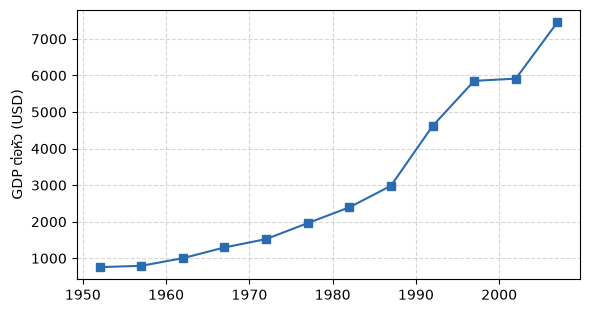

</div>

ไฟล์ `penguins_scatter.png` ถูกสร้างในโฟลเดอร์ที่รันโน้ตบุ๊ก — แนบลงรายงานได้ทันที

**เช็คลิสต์ "กราฟสื่อสารหรือยัง" — 4 ข้อ:**

1. **หัวเรื่องบอกข้อสรุป** — "ปีกยาวกว่าหนักกว่า" ไม่ใช่ "กราฟของเพนกวิน"
2. **หน่วยบนแกน** — (มม.) (กรัม) (ปี) — ไม่มีหน่วย = ไม่มีความหมาย
3. **legend ถ้ามีหลายกลุ่ม** — สีเปล่า ๆ ต้องเดาเอง
4. **แกนซื่อสัตย์** — bar เริ่มที่ศูนย์ ห้ามตัดฐาน

## 6. สรุป

- scatter = ความสัมพันธ์ · bar = เปรียบเทียบ · line = เวลา · histogram = รูปทรง
- สีคือตัวแปรที่สาม — ใส่แล้วเห็นกลุ่มที่ซ่อนอยู่ในเมฆ
- ตารางสรุปจาก `groupby` และ `groupby.agg()` (min/mean/max หรือหลายคอลัมน์) แปลงเป็นกราฟแท่งเดี่ยวและแท่งแบบกลุ่มได้ทันที
- กราฟแท่งเริ่มที่ศูนย์เสมอ — ความซื่อสัตย์สำคัญกว่าความดราม่า
- ป้ายครบ 4 ข้อ แล้ว `savefig` ไปเป็นไฟล์ภาพของรายงาน

นี่คือ**รูปแรกจากข้อมูลจริง**ของคุณ — วันที่ 1 ปิดตรงนี้: จากไฟล์ดิบเช้านี้
มาเป็นภาพที่สื่อสารได้ตอนนี้ เก็บไฟล์ `penguins_scatter.png` ไว้ดี ๆ
(ท้ายคอร์ส แบบฝึกปิดท้ายใน M7 จะให้เปิดกลับมาเทียบ)

**ต่อไป (M5):** พรุ่งนี้เริ่มด้วยสถิติ — ตัวเลขที่**ยืนยัน**สิ่งที่ตาเห็น
ในกราฟวันนี้ (กลุ่มซ่อนอยู่ · ต่างกันแค่ไหน) และเส้นในกราฟเวลา (line)
แบบนี้แหละที่จะกลายเป็น "การพยากรณ์" ใน M6 ซึ่งมีทั้งของดีและกับดักรออยู่